# Pole-on star, equatorial facula: is the disk intensity bumpy with rotation phase?

At i = 0 (pole-on; `simulator.py`: i = 90 deg is equator-on) an equatorial facula stays on the limb for the whole
rotation, so the disk-integrated intensity should be the same at every phase. Any variation with phase comes from
the grids: the facula moving across the 2D image pixels (res2d) and the healpix cells (res3d).

This compares an even and an odd 2D grid at two sizes: res2d = 200 vs 201 and 50 vs 51. For an odd res2d a pixel
centre sits on the disk centre (the pole here); for an even res2d the disk centre falls on a pixel corner.

Intensity only, at one wavelength: the facula is added with `ac.Simulator` and the disk summed with `rotate_lc`,
without the Doppler/spectral pipeline. Nothing is written to disk.

Run from `actress_highres/actress/` (all paths are relative to it).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import actress as ac
import actress.run_actress_notebook as actr

In [2]:
# ----- limb-darkening coefficients at one wavelength -----
# power2 fits written by the limb-darkening cell of Actress_4376_continuum_SSD.ipynb (columns: wavelength (m), I0, a, b).
hd_ld_file = 'test_phot_continuum_4376.txt'
fac_ld_file = 'test_fac_200G_4376.txt'
ld_law = 'power2'

hd_ld = np.loadtxt(hd_ld_file)
fac_ld = np.loadtxt(fac_ld_file)
if not np.array_equal(hd_ld[:, 0], fac_ld[:, 0]):
    raise ValueError(f"Wavelength grids of {hd_ld_file} and {fac_ld_file} differ")

# Line core, where the facula is darkest relative to the continuum photosphere, so its signal is largest.
core_wavelength = 4377.16e-10   # m
k_core = int(np.argmin(np.abs(hd_ld[:, 0] - core_wavelength)))
wavelength = hd_ld[k_core, 0]   # m
print(f"Using {wavelength * 1e10:.4f} A (row {k_core})")
print(f"phot I0, a, b = {hd_ld[k_core, 1:4]}")
print(f"fac  I0, a, b = {fac_ld[k_core, 1:4]}")

# The limb-darkening function Transitsim uses, taken from it rather than rewritten here.
ld_params = actr.Transitparams()
ld_params.ld = ld_law
ld_func = actr.Transitsim(ld_params).ld_law

Using 4377.1586 A (row 37)
phot I0, a, b = [42.59196504  0.87977542  0.80724089]
fac  I0, a, b = [4.11374935 1.46312037 0.22877009]


In [3]:
# ----- disk intensity against rotation phase -----
res2d_values = [50, 51, 200, 201]
res3d = 6          # healpix nside = 2^6, as in Actress_4376_continuum_SSD.ipynb
fac_r = 15         # deg, as in Actress_4376_continuum_SSD.ipynb
fac_long = 0       # deg
fac_lat = 0        # deg, equatorial: on the limb at i = 0
inc = 0            # deg, pole-on
n_phases = 1440    # 0.25 deg steps; a limb pixel at res2d = 200 spans ~0.6 deg of rotation, so each crossing is resolved
v_eq = 0           # m/s; only feeds the Doppler map, which is not used here

rotation_angles = np.linspace(0, 360, n_phases + 1)[:-1]   # deg, same grid as simulator.rotate_lc


def make_simulator(res2d, with_facula):
    sim = ac.Simulator(faculae=[], spots=[], fac_strips=[], spot_strips=[])   # explicit empty lists, as in Transitsim.actress_run
    sim.setxsize(res2d)
    sim.setresolution(res3d)
    sim.setld({'phot': list(hd_ld[k_core, 1:4]),
               'spot': list(hd_ld[k_core, 1:4]),   # no spots here; the spot mask is still built, so it needs coefficients
               'fac': list(fac_ld[k_core, 1:4]),
               'func': ld_func})
    if with_facula:
        sim.addfeature(r=fac_r, lon=fac_long, lat=fac_lat, feature='fac')
    # Builds the limb-darkening masks before rotate_lc. rotate_lc builds them lazily inside its threads, where one
    # thread can read the facular mask before another has finished it (TypeError: 'NoneType' ...). stellarmodel
    # builds them unless ldkey=True, so getdiscfill (ldkey=True) does not.
    sim.stellarmodel(inc=inc)
    return sim


def disk_intensity(sim, mode, n):
    # rotate_lc with returndisc=False gives the mean over the whole res2d x res2d image (off-disk pixels are 0).
    flux, _ = sim.rotate_lc(v_eq=v_eq, inc=inc, N=n, mode=mode, wavelength=wavelength * 1e10, returndisc=False)
    return np.asarray(flux)


results = {}
for res2d in res2d_values:
    active = disk_intensity(make_simulator(res2d, with_facula=True), 'faconly', n_phases)
    # A featureless star looks the same at every phase, so one phase is enough for the reference.
    quiet = disk_intensity(make_simulator(res2d, with_facula=False), 'quiet', 1)[0]
    if not np.all(np.isfinite(active)) or not np.isfinite(quiet):
        raise ValueError(f"Non-finite disk intensity at res2d {res2d}")
    contrast = (active - quiet) / quiet
    results[res2d] = {'active': active, 'quiet': quiet, 'contrast': contrast}
    print(f"res2d {res2d:3d}: contrast mean {contrast.mean():.4e}, "
          f"max - min {np.ptp(contrast):.3e} ({np.ptp(contrast) / abs(contrast.mean()) * 100:.2f}% of the mean)")

res2d  50: contrast mean -1.1437e-03, max - min 1.576e-03 (137.84% of the mean)


res2d  51: contrast mean -1.2096e-03, max - min 1.535e-03 (126.88% of the mean)


res2d 200: contrast mean -1.2871e-03, max - min 1.488e-04 (11.56% of the mean)


res2d 201: contrast mean -1.3136e-03, max - min 1.808e-04 (13.77% of the mean)


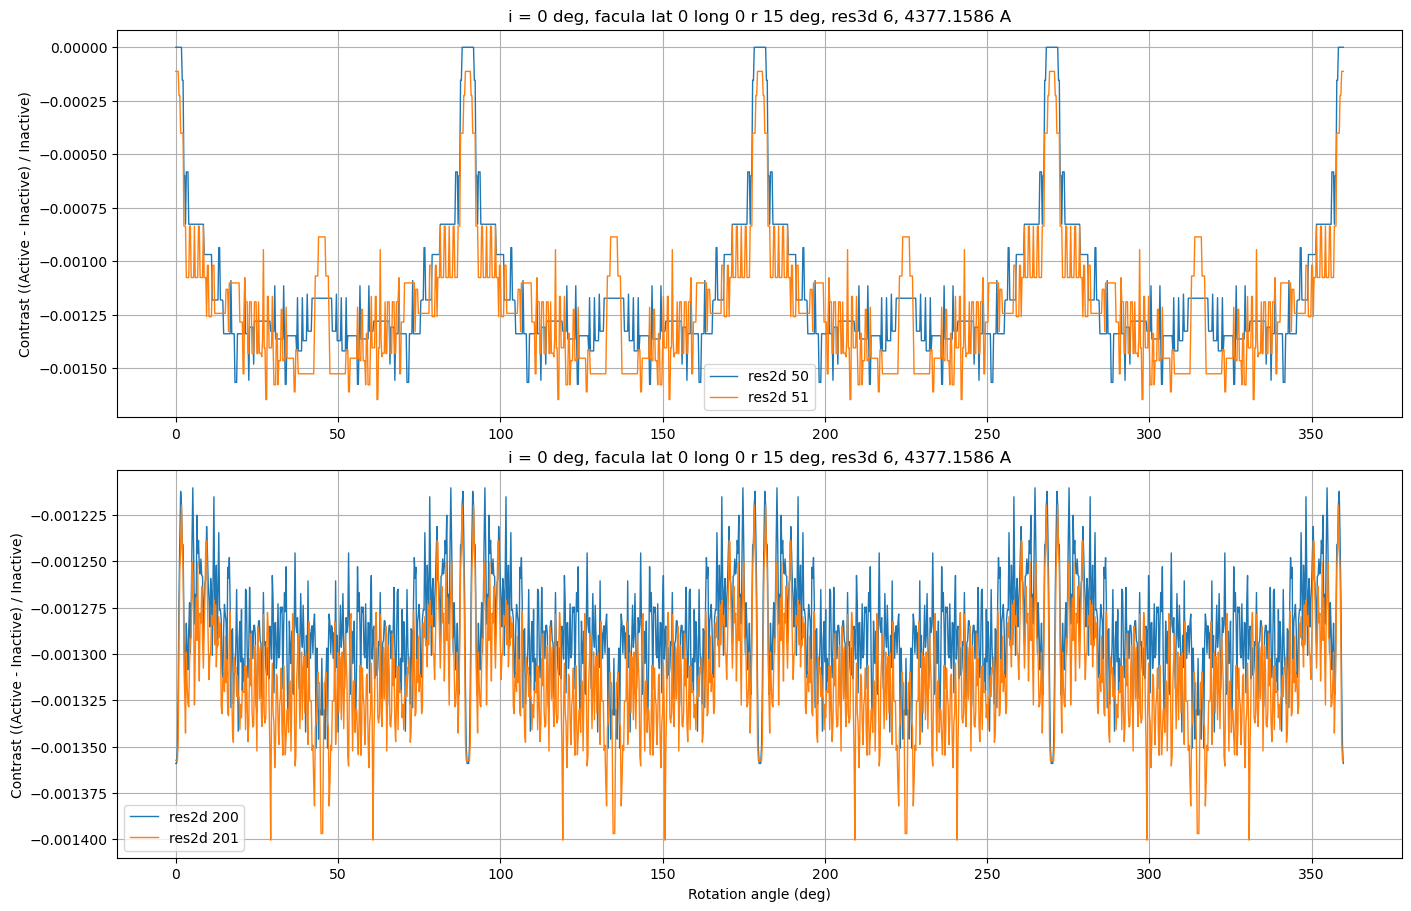

In [4]:
# ----- contrast against rotation angle: even vs odd res2d -----
fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
for ax, pair in zip(axes, [(50, 51), (200, 201)]):
    for res2d in pair:
        ax.plot(rotation_angles, results[res2d]['contrast'], linewidth=1, label=f'res2d {res2d}')
    ax.set_ylabel('Contrast ((Active - Inactive) / Inactive)')
    ax.set_title(f'i = {inc} deg, facula lat {fac_lat} long {fac_long} r {fac_r} deg, res3d {res3d}, {wavelength * 1e10:.4f} A')
    ax.legend()
    ax.grid(True)
axes[-1].set_xlabel('Rotation angle (deg)')
plt.show()

Expected healpix equator period: 1.406 deg
res2d  50: strongest cycles per turn [ 4  8 12 16 24] -> periods [90.  45.  30.  22.5 15. ] deg
res2d  51: strongest cycles per turn [ 4  8 16 40 24] -> periods [90.  45.  22.5  9.  15. ] deg
res2d 200: strongest cycles per turn [  4  16 100 104 124] -> periods [90.    22.5    3.6    3.462  2.903] deg
res2d 201: strongest cycles per turn [  4  96  24 104  16] -> periods [90.     3.75  15.     3.462 22.5  ] deg


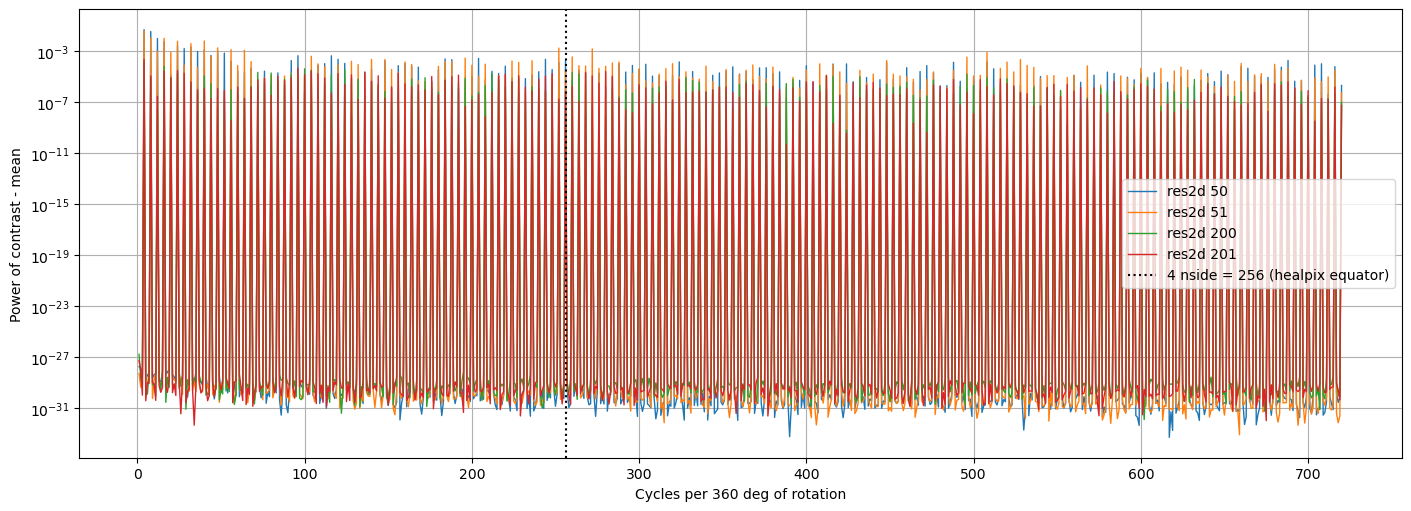

In [5]:
# ----- which periods the bumps repeat on -----
# The square 2D grid looks the same after a 90 deg turn about the disk centre, so bumps from it should repeat
# every 90 deg (or a divisor of it). The equator of an nside healpix map has 4 * nside cells, so bumps from the
# facula's own healpix outline should repeat every 360 / (4 * nside) deg.
nside = 2**res3d
print(f"Expected healpix equator period: {360 / (4 * nside):.3f} deg")

fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
for res2d in res2d_values:
    contrast = results[res2d]['contrast']
    power = np.abs(np.fft.rfft(contrast - contrast.mean()))**2
    cycles_per_turn = np.arange(len(power))   # rfft index k = k cycles per 360 deg
    ax.semilogy(cycles_per_turn[1:], power[1:], linewidth=1, label=f'res2d {res2d}')
    strongest = cycles_per_turn[1:][np.argsort(power[1:])[::-1][:5]]
    print(f"res2d {res2d:3d}: strongest cycles per turn {strongest} -> periods {np.round(360 / strongest, 3)} deg")
ax.axvline(4 * nside, color='k', linestyle=':', label=f'4 nside = {4 * nside} (healpix equator)')
ax.set_xlabel('Cycles per 360 deg of rotation')
ax.set_ylabel('Power of contrast - mean')
ax.legend()
ax.grid(True)
plt.show()